# 05 — Task 1 Experiments (C1–C4)

Satu varian per eksekusi:

- **C1**: baseline
- **C2**: tanpa CCA (ablasi)
- **C3**: hard-negative mining (mask sibling window)
- **C4**: dropout 0.2 + weight decay 1e-3

CCA **tidak diubah** di semua varian: `alpha=0.05`, `warmup_steps=200`, `r1=r2=rT=1e-3`.
Ubah `VARIANT` di cell konfigurasi, lalu Run All. Output ditulis ke
`reports/experiments/T1-<variant>_seed42/` dan `checkpoints/T1-<variant>_seed42/`.


In [1]:
from pathlib import Path
import json
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").exists():
    raise RuntimeError(f"Jalankan notebook dari root repo atau notebooks/. Path: {ROOT}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.baseline_dorfer import (
    DualEncoder,
    HardNegativeRankingLoss,
    PositivePairDataset,
    RankingLoss,
    build_positive_pairs,
    configure_torch,
    count_parameters,
    embed_audio_rows,
    embed_image_rows,
    hit_rate_at_k,
    load_checkpoint,
    load_split_frames,
    one_window_per_notehead,
    project_cca,
    ranks_from_multi_scores,
    ranks_from_scores,
    resolve_device,
    retrieval_metrics,
    save_json,
    set_seed,
    to_jsonable,
)

DATA_DIR = ROOT / "data" / "processed"
print("Root:", ROOT)
print("Data:", DATA_DIR)


Root: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning
Data: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\data\processed


In [2]:
VARIANT = "C3"  # C1 | C2 | C3 | C4
SEED = 42
OVERWRITE = False

if VARIANT not in {"C1", "C2", "C3", "C4"}:
    raise ValueError(f"Variant tidak dikenal: {VARIANT}")

RUN_ID = f"T1-{VARIANT}_seed{SEED}"
REPORTS_DIR = ROOT / "reports" / "experiments" / RUN_ID
FIG_DIR = REPORTS_DIR / "figures"
CKPT_DIR = ROOT / "checkpoints" / RUN_ID
for directory in (REPORTS_DIR, FIG_DIR, CKPT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

HISTORY_PATH = REPORTS_DIR / "history.csv"
METRICS_PATH = REPORTS_DIR / "metrics.json"
CONFIG_PATH = REPORTS_DIR / "config.json"
CHECKPOINT_PATH = CKPT_DIR / "best.pt"
EMBEDDINGS_PATH = CKPT_DIR / "test_embeddings.npz"

if METRICS_PATH.exists() and not OVERWRITE:
    raise RuntimeError(
        f"Run {RUN_ID} sudah ada. Set OVERWRITE=True untuk menimpa, "
        f"atau ganti VARIANT/SEED."
    )

print("Variant :", VARIANT)
print("Run ID  :", RUN_ID)
print("Reports :", REPORTS_DIR)
print("Ckpt    :", CKPT_DIR)


Variant : C3
Run ID  : T1-C3_seed42
Reports : E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\reports\experiments\T1-C3_seed42
Ckpt    : E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\checkpoints\T1-C3_seed42


In [3]:
BASE_CONFIG = {
    "profile": "dorfer-full",
    "seed": SEED,
    "device": "auto",
    "threads": None,
    "batch_size": 100,
    "eval_batch_size": 256,
    "epochs": 8,
    "early_stop_patience": 3,
    "lr": 2e-3,
    "weight_decay": 1e-4,
    "grad_clip": 5.0,
    "margin": 0.7,
    "embed_dim": 32,
    "channels": (24, 48, 96, 96),
    "use_cca": True,
    "cca": {"r1": 1e-3, "r2": 1e-3, "rT": 1e-3, "alpha": 0.05, "warmup_steps": 200},
    "augment": {
        "image_scale": (0.95, 1.05),
        "image_translate": 5.0,
        "audio_time_shift": 1,
        "audio_tempo_jitter": 0.1,
    },
    "num_workers": 0,
    "fast_dev": False,
    "dropout": 0.0,
    "mining": None,
    "mining_k": 10,
    "mining_warmup_epochs": 1,
}

VARIANT_DELTAS = {
    "C1": {},
    "C2": {"use_cca": False},
    "C3": {"mining": "hard", "mining_k": 10, "mining_warmup_epochs": 1},
    "C4": {"dropout": 0.2, "weight_decay": 1e-3},
}

CONFIG = dict(BASE_CONFIG)
CONFIG.update(VARIANT_DELTAS[VARIANT])
CONFIG["variant"] = VARIANT

assert CONFIG["cca"] == BASE_CONFIG["cca"], "Konfigurasi CCA berubah!"
assert CONFIG["cca"]["alpha"] == 0.05
assert CONFIG["cca"]["warmup_steps"] == 200
assert CONFIG["cca"]["r1"] == CONFIG["cca"]["r2"] == CONFIG["cca"]["rT"] == 1e-3

allowed = {
    "use_cca",
    "dropout",
    "weight_decay",
    "mining",
    "mining_k",
    "mining_warmup_epochs",
    "variant",
}
changed = {key for key in CONFIG if CONFIG[key] != BASE_CONFIG.get(key)}
assert changed <= allowed, f"Perubahan di luar rencana: {sorted(changed - allowed)}"

set_seed(int(CONFIG["seed"]))
configure_torch(CONFIG["threads"])
DEVICE = resolve_device(CONFIG["device"])

print("Config:")
print(json.dumps(to_jsonable(CONFIG), indent=2))
print("Device:", DEVICE)
print("Changed keys:", sorted(changed))


Config:
{
  "profile": "dorfer-full",
  "seed": 42,
  "device": "auto",
  "threads": null,
  "batch_size": 100,
  "eval_batch_size": 256,
  "epochs": 8,
  "early_stop_patience": 3,
  "lr": 0.002,
  "weight_decay": 0.0001,
  "grad_clip": 5.0,
  "margin": 0.7,
  "embed_dim": 32,
  "channels": [
    24,
    48,
    96,
    96
  ],
  "use_cca": true,
  "cca": {
    "r1": 0.001,
    "r2": 0.001,
    "rT": 0.001,
    "alpha": 0.05,
    "warmup_steps": 200
  },
  "augment": {
    "image_scale": [
      0.95,
      1.05
    ],
    "image_translate": 5.0,
    "audio_time_shift": 1,
    "audio_tempo_jitter": 0.1
  },
  "num_workers": 0,
  "fast_dev": false,
  "dropout": 0.0,
  "mining": "hard",
  "mining_k": 10,
  "mining_warmup_epochs": 1,
  "variant": "C3"
}
Device: cpu
Changed keys: ['mining', 'variant']


In [4]:
SPLITS = ["train", "val", "test"]
frames = {split: load_split_frames(DATA_DIR, split) for split in SPLITS}
positives = {
    split: build_positive_pairs(frames[split][2], frames[split][0], frames[split][1])
    for split in SPLITS
}

rows = []
for split in SPLITS:
    noteheads, windows, pairs = frames[split]
    rows.append({
        "split": split,
        "crops": len(noteheads),
        "windows": len(windows),
        "pairs": len(pairs),
        "positives": len(positives[split]),
        "pieces": noteheads["piece"].nunique(),
        "pages": noteheads["page_id"].nunique(),
        "windows_per_notehead_mean": round(
            windows.groupby("notehead_id").size().mean(), 3
        ),
    })
audit = pd.DataFrame(rows)
display(audit)

train_windows = frames["train"][1]
group_sizes = train_windows.groupby("notehead_id").size()
print("Train windows per notehead:", group_sizes.value_counts().to_dict())


,split,crops,windows,pairs,positives,pieces,pages,windows_per_notehead_mean
0,train,14365,28730,57460,28730,17,44,2.0
1,val,2430,9720,19440,9720,4,8,4.0
2,test,2018,8072,16144,8072,3,8,4.0


Train windows per notehead: {2: 14365}


In [5]:
train_pairs = positives["train"]
val_pairs = one_window_per_notehead(positives["val"])
USE_GROUP_IDS = CONFIG["mining"] == "hard"

train_dataset = PositivePairDataset(
    DATA_DIR / "score_crops_train.npy",
    DATA_DIR / "audio_windows_train.npy",
    train_pairs["crop_row"].to_numpy(),
    train_pairs["window_row_eval"].to_numpy(),
    augment=True,
    return_group_ids=USE_GROUP_IDS,
    **CONFIG["augment"],
)
val_dataset = PositivePairDataset(
    DATA_DIR / "score_crops_val.npy",
    DATA_DIR / "audio_windows_val.npy",
    val_pairs["crop_row"].to_numpy(),
    val_pairs["window_row_eval"].to_numpy(),
    augment=False,
    **CONFIG["augment"],
)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    drop_last=False,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["eval_batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
)

batch = next(iter(train_loader))
if USE_GROUP_IDS:
    images, specs, group_ids = batch
    n_sibling = len(group_ids) - len(set(group_ids.tolist()))
    print("group_ids sample:", group_ids[:10].tolist())
    print("sibling rows in batch:", n_sibling)
else:
    images, specs = batch

print("batch image:", tuple(images.shape), images.dtype)
print("batch audio:", tuple(specs.shape), specs.dtype)
assert images.shape[1:] == (1, 100, 80)
assert specs.shape[1:] == (1, 92, 42)
print(f"train batches: {len(train_loader):,} | val pairs: {len(val_dataset):,}")


group_ids sample: [12409, 139, 3104, 11860, 221, 4327, 3681, 643, 435, 8299]
sibling rows in batch: 0
batch image: (100, 1, 100, 80) torch.float32
batch audio: (100, 1, 92, 42) torch.float32
train batches: 288 | val pairs: 2,430


In [6]:
model = DualEncoder(
    embed_dim=CONFIG["embed_dim"],
    use_cca=CONFIG["use_cca"],
    cca_kwargs=CONFIG["cca"],
    channels=CONFIG["channels"],
    dropout=CONFIG["dropout"],
).to(DEVICE)

if CONFIG["mining"] == "hard":
    criterion = HardNegativeRankingLoss(
        margin=CONFIG["margin"],
        k=CONFIG["mining_k"],
        warmup_epochs=CONFIG["mining_warmup_epochs"],
    )
else:
    criterion = RankingLoss(margin=CONFIG["margin"])

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CONFIG["lr"],
    weight_decay=CONFIG["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
)

print(f"Total parameters: {count_parameters(model):,}")
print(f"Trainable       : {count_parameters(model, trainable_only=True):,}")
print("Criterion:", type(criterion).__name__)
print(model)


Total parameters: 662,000
Trainable       : 662,000
Criterion: HardNegativeRankingLoss
DualEncoder(
  (sheet): SheetEncoder(
    (blocks): Sequential(
      (0): ConvStack(
        (conv1): Conv2d(1, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act): ELU(alpha=1.0, inplace=True)
        (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): ConvStack(
        (conv1): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(48, 48, kernel_size=(3, 3), stride=(

In [7]:
def train_one_epoch(
    model, loader, optimizer, criterion, device, grad_clip, use_group_ids, epoch
):
    model.train()
    total_loss = 0.0
    total_items = 0
    for batch in loader:
        if use_group_ids:
            images, specs, group_ids = batch
            group_ids = group_ids.to(device, non_blocking=True)
        else:
            images, specs = batch
            group_ids = None
        images = images.to(device, non_blocking=True)
        specs = specs.to(device, non_blocking=True)
        z_sheet, z_audio = model(images, specs)
        if group_ids is not None:
            loss = criterion(z_sheet, z_audio, group_ids, epoch)
        else:
            loss = criterion(z_sheet, z_audio)
        if not torch.isfinite(loss):
            raise RuntimeError(
                "Loss tidak finite. Cek data, LR, atau stabilitas CCA."
            )
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if grad_clip:
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += float(loss.detach()) * images.size(0)
        total_items += images.size(0)
    return total_loss / max(total_items, 1)


@torch.no_grad()
def evaluate_val_mrr(model, loader, device):
    model.eval()
    images_all, specs_all = [], []
    for images, specs in loader:
        images_all.append(images)
        specs_all.append(specs)
    images_all = torch.cat(images_all, dim=0).to(device)
    specs_all = torch.cat(specs_all, dim=0).to(device)
    z_sheet, z_audio = model(images_all, specs_all)
    scores = (z_sheet @ z_audio.T).float().cpu().numpy()
    if not np.isfinite(scores).all():
        return {
            "mrr_a2s": float("nan"),
            "mrr_s2a": float("nan"),
            "mrr_mean": float("nan"),
            "n": int(scores.shape[0]),
        }
    targets = np.arange(scores.shape[0])
    ranks_a2s = ranks_from_scores(scores, targets)
    ranks_s2a = ranks_from_scores(scores.T, targets)
    mrr_a2s = float((1.0 / ranks_a2s).mean())
    mrr_s2a = float((1.0 / ranks_s2a).mean())
    return {
        "mrr_a2s": mrr_a2s,
        "mrr_s2a": mrr_s2a,
        "mrr_mean": 0.5 * (mrr_a2s + mrr_s2a),
        "n": int(scores.shape[0]),
    }


def fit(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    criterion,
    config,
    device,
    checkpoint_path,
    use_group_ids,
):
    history = []
    best_mrr = -1.0
    bad_epochs = 0
    for epoch in range(1, int(config["epochs"]) + 1):
        started = time.time()
        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device,
            config["grad_clip"],
            use_group_ids,
            epoch,
        )
        val_metrics = evaluate_val_mrr(model, val_loader, device)
        if not np.isfinite(val_metrics["mrr_mean"]):
            print("Val MRR tidak finite; training dihentikan.")
            break
        scheduler.step(val_metrics["mrr_mean"])
        elapsed = time.time() - started
        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics,
            "lr": float(optimizer.param_groups[0]["lr"]),
            "seconds": elapsed,
        }
        history.append(record)
        print(
            f"epoch {epoch:02d} | loss {train_loss:.4f} | "
            f"val MRR A2S {val_metrics['mrr_a2s']:.4f} | "
            f"val MRR S2A {val_metrics['mrr_s2a']:.4f} | "
            f"lr {record['lr']:.2e} | {elapsed:.1f}s"
        )
        if val_metrics["mrr_mean"] > best_mrr:
            best_mrr = val_metrics["mrr_mean"]
            bad_epochs = 0
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "sheet_encoder": model.sheet.state_dict(),
                    "audio_encoder": model.audio.state_dict(),
                    "config": config,
                    "variant": config.get("variant"),
                    "epoch": epoch,
                    "val_metrics": val_metrics,
                },
                checkpoint_path,
            )
            print(f"  -> checkpoint disimpan (best val MRR {best_mrr:.4f})")
        else:
            bad_epochs += 1
            if bad_epochs >= int(config["early_stop_patience"]):
                print(f"Early stop setelah {bad_epochs} epoch tanpa perbaikan.")
                break
    return history, best_mrr


In [8]:
FAST_DEV_RUN = bool(CONFIG["fast_dev"])
run_train_loader = train_loader
run_val_loader = val_loader
run_epochs = int(CONFIG["epochs"])
run_patience = int(CONFIG["early_stop_patience"])

if FAST_DEV_RUN:
    run_train_loader = DataLoader(
        Subset(train_dataset, range(min(2000, len(train_dataset)))),
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        num_workers=CONFIG["num_workers"],
    )
    run_val_loader = DataLoader(
        Subset(val_dataset, range(min(500, len(val_dataset)))),
        batch_size=CONFIG["eval_batch_size"],
        shuffle=False,
        num_workers=CONFIG["num_workers"],
    )
    run_epochs = 2
    run_patience = 2
    print("FAST_DEV_RUN aktif: 2.000 train pairs, 500 val pairs, 2 epoch.")

fit_config = dict(CONFIG)
fit_config["epochs"] = run_epochs
fit_config["early_stop_patience"] = run_patience

history, best_mrr = fit(
    model,
    run_train_loader,
    run_val_loader,
    optimizer,
    scheduler,
    criterion,
    fit_config,
    DEVICE,
    CHECKPOINT_PATH,
    USE_GROUP_IDS,
)
print(f"Best validation MRR: {best_mrr:.4f}")
print("Checkpoint:", CHECKPOINT_PATH)

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv(HISTORY_PATH, index=False)


epoch 01 | loss 0.2211 | val MRR A2S 0.0047 | val MRR S2A 0.0043 | lr 2.00e-03 | 475.0s
  -> checkpoint disimpan (best val MRR 0.0045)


epoch 02 | loss 0.4144 | val MRR A2S 0.0160 | val MRR S2A 0.0137 | lr 2.00e-03 | 473.0s
  -> checkpoint disimpan (best val MRR 0.0148)


epoch 03 | loss 0.2216 | val MRR A2S 0.0206 | val MRR S2A 0.0166 | lr 2.00e-03 | 467.3s
  -> checkpoint disimpan (best val MRR 0.0186)


epoch 04 | loss 0.1616 | val MRR A2S 0.0259 | val MRR S2A 0.0194 | lr 2.00e-03 | 466.1s
  -> checkpoint disimpan (best val MRR 0.0226)


epoch 05 | loss 0.1379 | val MRR A2S 0.0231 | val MRR S2A 0.0199 | lr 2.00e-03 | 461.1s


epoch 06 | loss 0.1221 | val MRR A2S 0.0176 | val MRR S2A 0.0152 | lr 2.00e-03 | 483.8s


epoch 07 | loss 0.1148 | val MRR A2S 0.0160 | val MRR S2A 0.0117 | lr 1.00e-03 | 459.3s
Early stop setelah 3 epoch tanpa perbaikan.
Best validation MRR: 0.0226
Checkpoint: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\checkpoints\T1-C3_seed42\best.pt


,epoch,train_loss,mrr_a2s,mrr_s2a,mrr_mean,n,lr,seconds
0,1,0.221117,0.004744,0.004283,0.004514,2430,0.002,475.048001
1,2,0.414449,0.015956,0.013694,0.014825,2430,0.002,472.990718
2,3,0.221603,0.020578,0.016551,0.018564,2430,0.002,467.294290
3,4,0.161566,0.025887,0.019390,0.022638,2430,0.002,466.089945
4,5,0.137888,0.023090,0.019900,0.021495,2430,0.002,461.118566
5,6,0.122109,0.017607,0.015221,0.016414,2430,0.002,483.782528
6,7,0.114769,0.016015,0.011666,0.013841,2430,0.001,459.302865


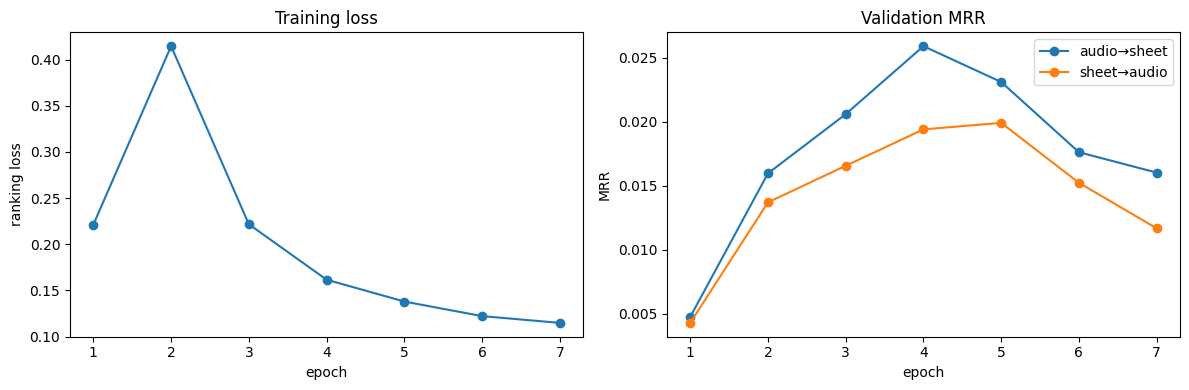

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("ranking loss")
axes[0].set_title("Training loss")
axes[1].plot(history_df["epoch"], history_df["mrr_a2s"], marker="o", label="audio→sheet")
axes[1].plot(history_df["epoch"], history_df["mrr_s2a"], marker="o", label="sheet→audio")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("MRR")
axes[1].set_title("Validation MRR")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
checkpoint = load_checkpoint(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()
print("Loaded epoch", checkpoint.get("epoch"), "| val:", checkpoint.get("val_metrics"))

noteheads_test, windows_test, pairs_test = frames["test"]
noteheads_test = noteheads_test.sort_values("crop_row").reset_index(drop=True)
windows_test = windows_test.sort_values("window_row").reset_index(drop=True)
assert np.array_equal(
    noteheads_test["crop_row"].to_numpy(), np.arange(len(noteheads_test))
)
assert np.array_equal(
    windows_test["window_row"].to_numpy(), np.arange(len(windows_test))
)

notehead_ids = noteheads_test["notehead_id"].tolist()
notehead_to_index = {
    notehead_id: index for index, notehead_id in enumerate(notehead_ids)
}

sheet_hidden = embed_image_rows(
    model.sheet,
    DATA_DIR / "score_crops_test.npy",
    noteheads_test["crop_row"].to_numpy(),
    batch_size=CONFIG["eval_batch_size"],
    device=DEVICE,
)
audio_hidden = embed_audio_rows(
    model.audio,
    DATA_DIR / "audio_windows_test.npy",
    windows_test["window_row"].to_numpy(),
    batch_size=CONFIG["eval_batch_size"],
    device=DEVICE,
)

if model.cca is not None:
    z_sheet = project_cca(
        sheet_hidden.to(DEVICE),
        model.cca.mean1.detach(),
        model.cca.U.detach(),
    ).cpu()
    z_audio = project_cca(
        audio_hidden.to(DEVICE),
        model.cca.mean2.detach(),
        model.cca.V.detach(),
    ).cpu()
else:
    z_sheet = F.normalize(sheet_hidden, dim=1)
    z_audio = F.normalize(audio_hidden, dim=1)

print("z_sheet:", tuple(z_sheet.shape), "| z_audio:", tuple(z_audio.shape))
assert z_sheet.shape == (len(noteheads_test), CONFIG["embed_dim"])
assert z_audio.shape == (len(windows_test), CONFIG["embed_dim"])
assert torch.isfinite(z_sheet).all() and torch.isfinite(z_audio).all()


Loaded epoch 4 | val: {'mrr_a2s': 0.025887121186489104, 'mrr_s2a': 0.019389766437482105, 'mrr_mean': 0.022638443811985605, 'n': 2430}


z_sheet: (2018, 32) | z_audio: (8072, 32)


In [11]:
similarity = (z_audio @ z_sheet.T).numpy()
assert np.isfinite(similarity).all()

window_targets = windows_test["notehead_id"].map(notehead_to_index).to_numpy()
assert not np.isnan(window_targets).any()
window_targets = window_targets.astype(int)

paired = one_window_per_notehead(
    build_positive_pairs(pairs_test, noteheads_test, windows_test)
)
paired_window_rows = paired["window_row_eval"].to_numpy()
paired_targets = paired["notehead_id"].map(notehead_to_index).to_numpy().astype(int)
assert len(paired) == len(noteheads_test)
assert np.array_equal(np.sort(paired_targets), np.arange(len(noteheads_test)))

similarity_paired = similarity[paired_window_rows]
ranks_paired_a2s = ranks_from_scores(similarity_paired, paired_targets)

inverse_paired_targets = np.empty_like(paired_targets)
inverse_paired_targets[paired_targets] = np.arange(len(paired_targets))
ranks_paired_s2a = ranks_from_scores(similarity_paired.T, inverse_paired_targets)

ranks_extended_a2s = ranks_from_scores(similarity, window_targets)
target_lists = [
    np.flatnonzero(window_targets == index) for index in range(len(noteheads_test))
]
ranks_extended_s2a = ranks_from_multi_scores(similarity.T, target_lists)

rng = np.random.default_rng(SEED)
shuffled_queries = rng.permutation(len(paired))
ranks_random = ranks_from_scores(
    similarity_paired[shuffled_queries],
    paired_targets,
)

snippet_metrics = {
    "paired_2018_audio_to_sheet": retrieval_metrics(ranks_paired_a2s),
    "paired_2018_sheet_to_audio": retrieval_metrics(ranks_paired_s2a),
    "extended_audio_to_sheet": retrieval_metrics(ranks_extended_a2s),
    "extended_sheet_to_audio": retrieval_metrics(ranks_extended_s2a),
    "random_paired_audio_to_sheet": retrieval_metrics(ranks_random),
}
display(
    pd.DataFrame({
        "protocol": list(snippet_metrics.keys()),
        **{
            metric: [value.get(metric) for value in snippet_metrics.values()]
            for metric in ("R@1", "R@5", "R@10", "R@25", "MRR", "median_rank")
        },
    })
)


,protocol,R@1,R@5,R@10,R@25,MRR,median_rank
0,paired_2018_audio_to_sheet,0.004955,0.019822,0.033697,0.068385,0.017444,721.5
1,paired_2018_sheet_to_audio,0.008424,0.021804,0.039148,0.073835,0.020038,721.5
2,extended_audio_to_sheet,0.007061,0.027502,0.050050,0.102577,0.024119,551.5
3,extended_sheet_to_audio,0.008920,0.028741,0.045094,0.086720,0.022899,885.0
4,random_paired_audio_to_sheet,0.000991,0.001982,0.003469,0.011397,0.004096,1006.0


In [12]:
nh_systems = pd.read_parquet(DATA_DIR / "notehead_systems_test.parquet")
systems = pd.read_parquet(DATA_DIR / "systems_test.parquet")
pairs_system = pd.read_parquet(DATA_DIR / "pairs_system_test.parquet")

system_ids = systems["system_id"].tolist()
system_to_col = {system_id: index for index, system_id in enumerate(system_ids)}
assert pairs_system["candidate_system_id"].isin(system_ids).all()
assert pairs_system["positive_system_id"].isin(system_ids).all()
nh_systems["notehead_index"] = nh_systems["notehead_id"].map(notehead_to_index)
assert nh_systems["notehead_index"].notna().all()
nh_systems["notehead_index"] = nh_systems["notehead_index"].astype(int)

system_notehead_indices = {
    system_id: nh_systems.loc[
        nh_systems["system_id"] == system_id, "notehead_index"
    ].to_numpy()
    for system_id in system_ids
}
system_scores = np.full((len(windows_test), len(system_ids)), -np.inf, dtype=np.float32)
for system_id, indices in system_notehead_indices.items():
    if len(indices):
        system_scores[:, system_to_col[system_id]] = similarity[:, indices].max(axis=1)

notehead_to_system = nh_systems.set_index("notehead_id")["system_id"].to_dict()
window_true_system = windows_test["notehead_id"].map(notehead_to_system)
assert window_true_system.notna().all()
window_true_system_col = window_true_system.map(system_to_col).to_numpy().astype(int)

ranks_system_full = ranks_from_scores(system_scores, window_true_system_col)

page_to_systems = systems.groupby("page_id")["system_id"].apply(list).to_dict()
window_pages = windows_test["page_id"].to_numpy()
ranks_system_page = np.empty(len(windows_test), dtype=np.int64)
for index in range(len(windows_test)):
    candidate_systems = page_to_systems[window_pages[index]]
    candidate_cols = np.asarray(
        [system_to_col[s] for s in candidate_systems], dtype=int
    )
    true_col = window_true_system_col[index]
    assert true_col in candidate_cols, "True system tidak ada di halaman query."
    scores = system_scores[index, candidate_cols]
    true_score = system_scores[index, true_col]
    ranks_system_page[index] = int((scores > true_score).sum()) + 1

ranks_system_5 = []
system5_pieces = []
window_piece_map = windows_test.set_index("window_row")["piece"].to_dict()
for _, group in pairs_system.groupby("query_id", sort=False):
    row = int(group["window_row"].iloc[0])
    candidate_cols = group["candidate_system_id"].map(system_to_col).to_numpy()
    scores = system_scores[row, candidate_cols]
    positive_id = group.loc[group["label"] == 1, "candidate_system_id"].iloc[0]
    positive_position = int(
        np.flatnonzero(group["candidate_system_id"].to_numpy() == positive_id)[0]
    )
    ranks_system_5.append(int((scores > scores[positive_position]).sum()) + 1)
    system5_pieces.append(window_piece_map[row])
ranks_system_5 = np.asarray(ranks_system_5)
system5_pieces = np.asarray(system5_pieces)

system_metrics = {
    "page_conditioned": retrieval_metrics(ranks_system_page),
    "full_collection": retrieval_metrics(ranks_system_full),
    "five_candidate": retrieval_metrics(ranks_system_5),
}
display(pd.DataFrame(system_metrics).T)


,R@1,R@5,R@10,R@25,MRR,median_rank,mean_rank,n_queries
page_conditioned,0.281467,0.970763,1.000000,1.000000,0.530430,2.0,2.644822,8072.0
full_collection,0.108028,0.341551,0.490089,0.764123,0.232523,11.0,14.142963,8072.0
five_candidate,0.295590,1.000000,1.000000,1.000000,0.541495,2.0,2.551165,8072.0


In [13]:
notehead_piece = noteheads_test["piece"].to_numpy()
notehead_page = noteheads_test["page_id"].to_numpy()
window_piece = windows_test["piece"].to_numpy()
window_page = windows_test["page_id"].to_numpy()

piece_names = sorted(set(window_piece))
piece_to_id = {name: index for index, name in enumerate(piece_names)}
page_names = sorted(set(window_page))
page_to_id = {name: index for index, name in enumerate(page_names)}


def vote_rank(labels_per_candidate, true_label, label_to_id, num_labels):
    votes = np.zeros(num_labels, dtype=np.int64)
    for label in labels_per_candidate:
        votes[label_to_id[label]] += 1
    true_id = label_to_id[true_label]
    order = np.argsort(-votes, kind="stable")
    return int(np.flatnonzero(order == true_id)[0]) + 1


top_k = 25
top_noteheads = np.argsort(-similarity, axis=1)[:, :top_k]
ranks_piece_a2s, ranks_page_a2s = [], []
for index in range(len(windows_test)):
    candidate_ids = top_noteheads[index]
    ranks_piece_a2s.append(
        vote_rank(
            notehead_piece[candidate_ids],
            window_piece[index],
            piece_to_id,
            len(piece_names),
        )
    )
    ranks_page_a2s.append(
        vote_rank(
            notehead_page[candidate_ids],
            window_page[index],
            page_to_id,
            len(page_names),
        )
    )

top_windows = np.argsort(-similarity.T, axis=1)[:, :top_k]
ranks_piece_s2a, ranks_page_s2a = [], []
for index in range(len(noteheads_test)):
    candidate_ids = top_windows[index]
    ranks_piece_s2a.append(
        vote_rank(
            window_piece[candidate_ids],
            notehead_piece[index],
            piece_to_id,
            len(piece_names),
        )
    )
    ranks_page_s2a.append(
        vote_rank(
            window_page[candidate_ids],
            notehead_page[index],
            page_to_id,
            len(page_names),
        )
    )

identification_metrics = {
    "piece_audio_to_sheet_top25": hit_rate_at_k(ranks_piece_a2s),
    "piece_sheet_to_audio_top25": hit_rate_at_k(ranks_piece_s2a),
    "page_audio_to_sheet_top25": hit_rate_at_k(ranks_page_a2s),
    "page_sheet_to_audio_top25": hit_rate_at_k(ranks_page_s2a),
}
display(pd.DataFrame(identification_metrics).T)


,Rk@1,Rk@1_pct,Rk@5,Rk@5_pct,Rk@10,Rk@10_pct,n_queries
piece_audio_to_sheet_top25,3947.0,0.488974,8072.0,1.000000,8072.0,1.0,8072.0
piece_sheet_to_audio_top25,1048.0,0.519326,2018.0,1.000000,2018.0,1.0,2018.0
page_audio_to_sheet_top25,2701.0,0.334613,6840.0,0.847374,8072.0,1.0,8072.0
page_sheet_to_audio_top25,691.0,0.342418,1805.0,0.894450,2018.0,1.0,2018.0


In [14]:
def per_piece_metrics(piece_name):
    result = {}
    paired_mask = paired["piece"].to_numpy() == piece_name
    if paired_mask.any():
        result["snippet_paired_a2s"] = retrieval_metrics(
            ranks_paired_a2s[paired_mask]
        )
        result["snippet_paired_s2a"] = retrieval_metrics(
            ranks_paired_s2a[paired_mask]
        )

    window_mask = windows_test["piece"].to_numpy() == piece_name
    notehead_mask = noteheads_test["piece"].to_numpy() == piece_name
    if window_mask.any():
        result["system_full"] = retrieval_metrics(ranks_system_full[window_mask])
        result["system_page"] = retrieval_metrics(ranks_system_page[window_mask])
        result["identification_page_a2s"] = hit_rate_at_k(
            np.asarray(ranks_page_a2s)[window_mask]
        )
    if notehead_mask.any():
        result["identification_page_s2a"] = hit_rate_at_k(
            np.asarray(ranks_page_s2a)[notehead_mask]
        )

    system5_mask = system5_pieces == piece_name
    if system5_mask.any():
        result["system_five_candidate"] = retrieval_metrics(
            ranks_system_5[system5_mask]
        )
    return result


per_piece = {piece: per_piece_metrics(piece) for piece in piece_names}
display(
    pd.DataFrame({
        piece: {
            "snippet_a2s_R@1": values.get("snippet_paired_a2s", {}).get("R@1"),
            "snippet_a2s_MRR": values.get("snippet_paired_a2s", {}).get("MRR"),
            "system5_R@1": values.get("system_five_candidate", {}).get("R@1"),
            "system_full_R@1": values.get("system_full", {}).get("R@1"),
            "system_full_MRR": values.get("system_full", {}).get("MRR"),
        }
        for piece, values in per_piece.items()
    }).T
)

chance_metrics = {
    "snippet_paired_a2s_r1": 1.0 / len(noteheads_test),
    "system_full_r1": 1.0 / len(system_ids),
    "system_five_candidate_r1": 1.0 / 5.0,
    "system_page_conditioned_r1": float(
        np.mean([1.0 / len(page_to_systems[page]) for page in window_pages])
    ),
    "identification_piece_top25": 1.0 / len(piece_names),
    "identification_page_top25": 1.0 / len(page_names),
}
display(pd.Series(chance_metrics, name="chance").to_frame())


,snippet_a2s_R@1,snippet_a2s_MRR,system5_R@1,system_full_R@1,system_full_MRR
ChopinFF__B130__TroisNouvellesEtudes_Chopin_n1,0.002601,0.007375,0.148244,0.040962,0.103446
KumarR__lani__lani,0.001435,0.009209,0.368364,0.100789,0.258910
MagnenatS__variations-automne__variations-automne,0.012681,0.041869,0.408967,0.210598,0.379025


,chance
snippet_paired_a2s_r1,0.000496
system_full_r1,0.027778
system_five_candidate_r1,0.200000
system_page_conditioned_r1,0.216022
identification_piece_top25,0.333333
identification_page_top25,0.125000


In [15]:
git_commit = None
try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True
    ).strip()
except Exception:
    pass

primary_metrics = {
    "snippet_paired_a2s_r1": snippet_metrics["paired_2018_audio_to_sheet"]["R@1"],
    "snippet_paired_a2s_mrr": snippet_metrics["paired_2018_audio_to_sheet"]["MRR"],
    "system_five_candidate_r1": system_metrics["five_candidate"]["R@1"],
    "system_full_mrr": system_metrics["full_collection"]["MRR"],
}

metrics_payload = {
    "paper": "Dorfer et al. (2018), TISMIR 1(1):22-33",
    "task": "Task 1 - score-audio alignment / system localization",
    "variant": VARIANT,
    "run_id": RUN_ID,
    "config": CONFIG,
    "base_config": BASE_CONFIG,
    "seed": SEED,
    "device": str(DEVICE),
    "git_commit": git_commit,
    "checkpoint": str(CHECKPOINT_PATH),
    "best_checkpoint_epoch": checkpoint.get("epoch"),
    "best_val_metrics": checkpoint.get("val_metrics"),
    "snippet_retrieval": snippet_metrics,
    "system_localization": system_metrics,
    "identification": identification_metrics,
    "per_piece": per_piece,
    "chance": chance_metrics,
    "primary": primary_metrics,
    "history": history,
}
save_json(METRICS_PATH, metrics_payload)
save_json(CONFIG_PATH, {
    "variant": VARIANT,
    "run_id": RUN_ID,
    "config": CONFIG,
    "base_config": BASE_CONFIG,
    "git_commit": git_commit,
})
np.savez_compressed(
    EMBEDDINGS_PATH,
    sheet=z_sheet.numpy(),
    audio=z_audio.numpy(),
    notehead_ids=np.asarray(notehead_ids),
    window_ids=windows_test["window_id"].to_numpy(),
)
print("Disimpan:", METRICS_PATH)
print("Disimpan:", CONFIG_PATH)
print("Disimpan:", EMBEDDINGS_PATH)
print("Primary:", json.dumps(to_jsonable(primary_metrics), indent=2))


Disimpan: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\reports\experiments\T1-C3_seed42\metrics.json
Disimpan: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\reports\experiments\T1-C3_seed42\config.json
Disimpan: E:\SMT 5\ML\Projek-Dofter-Full\msmd-learning\checkpoints\T1-C3_seed42\test_embeddings.npz
Primary: {
  "snippet_paired_a2s_r1": 0.004955401387512388,
  "snippet_paired_a2s_mrr": 0.01744371645742388,
  "system_five_candidate_r1": 0.295589692765114,
  "system_full_mrr": 0.23252328644274872
}


In [16]:
summary = pd.DataFrame([
    {
        "metric": "val_mrr_mean",
        "value": checkpoint.get("val_metrics", {}).get("mrr_mean"),
    },
    {
        "metric": "snippet_paired_a2s_R@1",
        "value": primary_metrics["snippet_paired_a2s_r1"],
    },
    {
        "metric": "snippet_paired_a2s_MRR",
        "value": primary_metrics["snippet_paired_a2s_mrr"],
    },
    {
        "metric": "system_5cand_R@1",
        "value": primary_metrics["system_five_candidate_r1"],
    },
    {
        "metric": "system_full_MRR",
        "value": primary_metrics["system_full_mrr"],
    },
])
display(summary)
print("Langkah berikutnya: jalankan VARIANT berikutnya dengan OVERWRITE=False.")


,metric,value
0,val_mrr_mean,0.022638
1,snippet_paired_a2s_R@1,0.004955
2,snippet_paired_a2s_MRR,0.017444
3,system_5cand_R@1,0.295590
4,system_full_MRR,0.232523


Langkah berikutnya: jalankan VARIANT berikutnya dengan OVERWRITE=False.
